(200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


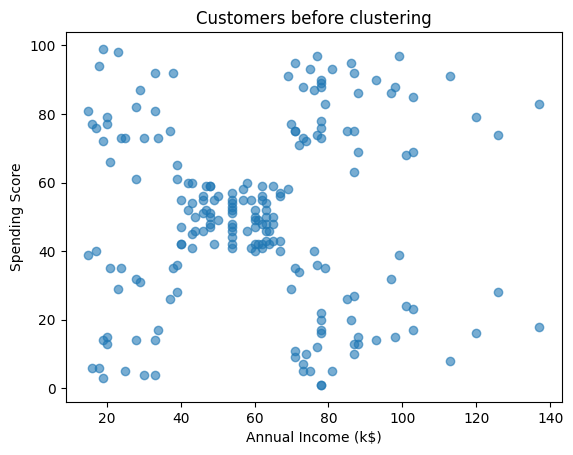

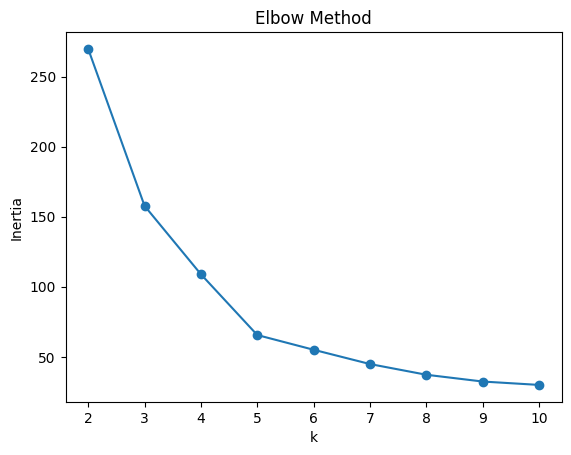

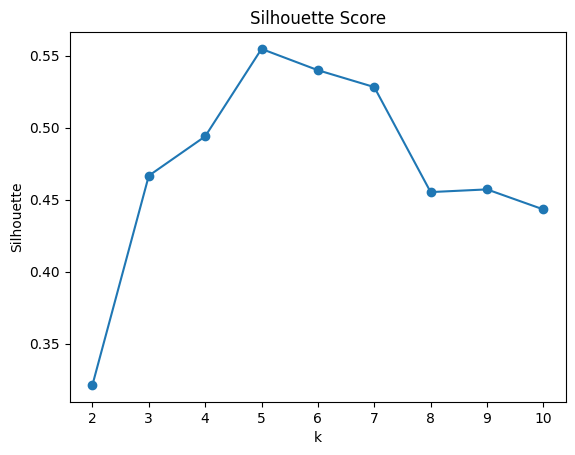

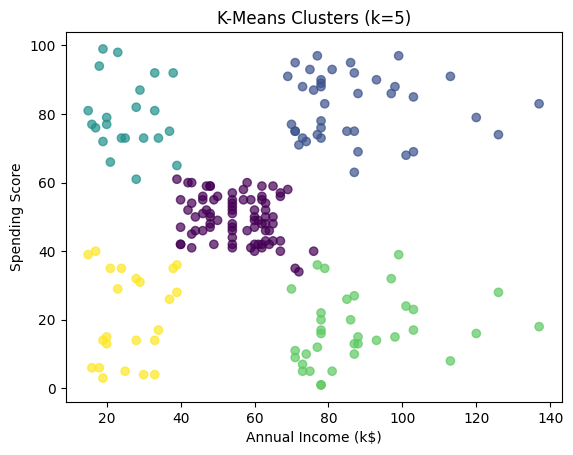

         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                      55.3                    49.5
1                      86.5                    82.1
2                      25.7                    79.4
3                      88.2                    17.1
4                      26.3                    20.9


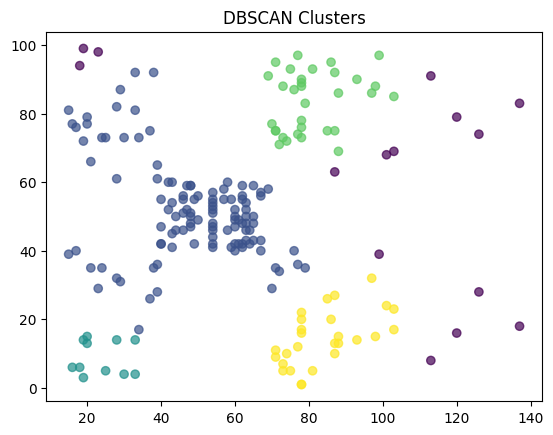

DBSCAN clusters found: 4
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                      55.3                    49.5
1                      86.5                    82.1
2                      25.7                    79.4
3                      88.2                    17.1
4                      26.3                    20.9


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

df = pd.read_csv("Mall_Customers.csv")
print(df.shape)
print(df.head())
print(df.isnull().sum())

cols = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[cols]

plt.scatter(X[cols[0]], X[cols[1]], alpha=0.6)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title("Customers before clustering")
plt.show()

X_scaled = StandardScaler().fit_transform(X)

inertia, sil = [], []
ks = range(2, 11)
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

plt.plot(ks, inertia, marker="o")
plt.xlabel("k"); plt.ylabel("Inertia"); plt.title("Elbow Method")
plt.show()

plt.plot(ks, sil, marker="o")
plt.xlabel("k"); plt.ylabel("Silhouette"); plt.title("Silhouette Score")
plt.show()

best_k = 5
km = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit(X_scaled)
df["Cluster"] = km.labels_

plt.scatter(X[cols[0]], X[cols[1]], c=df["Cluster"], cmap="viridis", alpha=0.7)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title(f"K-Means Clusters (k={best_k})")
plt.show()

print(df.groupby("Cluster")[cols].mean().round(1))
db = DBSCAN(eps=0.4, min_samples=5).fit(X_scaled)
plt.scatter(X[cols[0]], X[cols[1]], c=db.labels_, cmap="viridis", alpha=0.7)
plt.title("DBSCAN Clusters")
plt.show()
print("DBSCAN clusters found:", len(set(db.labels_)) - (1 if -1 in db.labels_ else 0))

print(df.groupby("Cluster")[cols].mean().round(1))